# Tugas Praktikum — K-Means & DBSCAN

**Dataset K-Means:** `Mall_Customers.csv` (file yang dilampirkan pengguna, 200 data).  
**Dataset DBSCAN:** data sintetis `make_moons` (1000 sampel).  
**Tujuan:** seleksi fitur, penentuan *k* optimal dengan Elbow & Silhouette, clustering pelanggan, evaluasi DBSCAN, dan eksperimen `eps`/`min_samples`.


## Bagian A — K-Means: Mall Customers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, homogeneity_score,
    completeness_score, v_measure_score, adjusted_rand_score,
    adjusted_mutual_info_score)

# Load file lokal. Di Colab akan meminta unggah bila belum ada.
file_path = Path('Mall_Customers.csv')
if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = Path('Mall_Customers.csv')
    except ImportError:
        raise FileNotFoundError('Letakkan Mall_Customers.csv di folder yang sama dengan notebook.')

df = pd.read_csv(file_path)
print('Ukuran dataset:', df.shape)
print('Jumlah missing value per kolom:')
print(df.isna().sum())
display(df.head())

Ukuran dataset: (200, 5)
Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1. Seleksi fitur

- **Digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)` — merepresentasikan pendapatan dan kebiasaan berbelanja.
- **Tidak digunakan:** `CustomerID` (hanya penanda unik), `Gender` dan `Age` (tidak dipilih karena analisis ini fokus pada segmentasi perilaku pendapatan–belanja).

Dua fitur berada pada rentang numerik yang relatif sebanding; model di bawah menggunakan nilai asli agar centroid mudah diinterpretasikan.

Jumlah fitur terpilih: 2


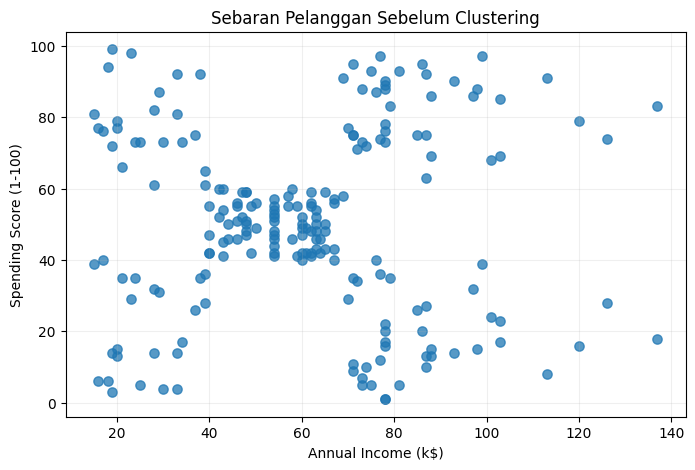

In [2]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
print('Jumlah fitur terpilih:', X.shape[1])
plt.figure(figsize=(8,5))
plt.scatter(X.iloc[:,0],X.iloc[:,1],s=45,alpha=0.75)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Sebaran Pelanggan Sebelum Clustering')
plt.grid(alpha=.2)
plt.show()

### 2. Pemilihan k dengan Elbow dan Silhouette

,k,SSE,Silhouette
0,1,269981.2800,NaN
1,2,181363.5960,0.2969
2,3,106348.3731,0.4676
3,4,73679.7890,0.4932
4,5,44448.4554,0.5539
5,6,37233.8145,0.5398
6,7,30241.3436,0.5288
7,8,25036.4176,0.4548
8,9,21916.7948,0.4561
9,10,20072.0709,0.4411


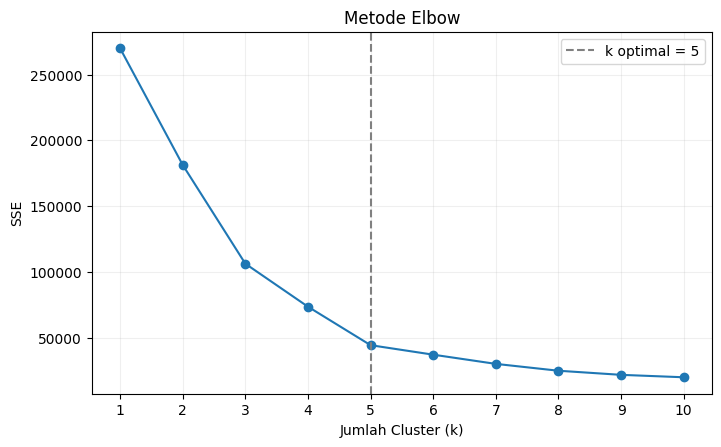

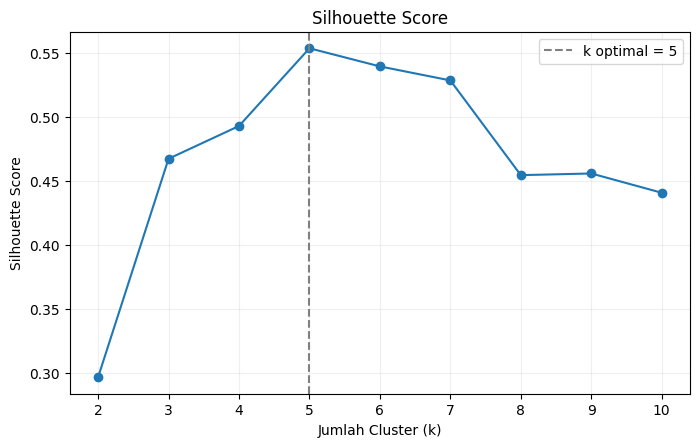

In [3]:
k_values = range(1,11)
sse = []
silhouette_values = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    predicted = km.fit_predict(X)
    sse.append(km.inertia_)
    silhouette_values.append(silhouette_score(X, predicted) if k>=2 else np.nan)

nilai_k = pd.DataFrame({'k':list(k_values), 'SSE':sse, 'Silhouette':silhouette_values})
display(nilai_k.round(4))

plt.figure(figsize=(8,4.7))
plt.plot(list(k_values),sse,marker='o')
plt.axvline(5,ls='--',color='gray',label='k optimal = 5')
plt.title('Metode Elbow')
plt.xlabel('Jumlah Cluster (k)');plt.ylabel('SSE')
plt.xticks(list(k_values));plt.grid(alpha=.2);plt.legend();plt.show()

plt.figure(figsize=(8,4.7))
plt.plot(list(k_values)[1:],silhouette_values[1:],marker='o')
plt.axvline(5,ls='--',color='gray',label='k optimal = 5')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (k)');plt.ylabel('Silhouette Score')
plt.xticks(list(k_values)[1:]);plt.grid(alpha=.2);plt.legend();plt.show()

### 3. Model akhir K-Means (k=5)

Metode Elbow memperlihatkan titik siku pada **k=5**; Silhouette Score tertinggi dalam rentang k=2–10 juga diperoleh pada **k=5**. Nomor label cluster hanya penanda, bukan urutan ranking.

SSE: 44448.4554
Silhouette: 0.5539


,Jumlah_Pelanggan,Mean_Income,Mean_Spending,Segmen
Cluster,,,,
0,81,55.30,49.52,Pendapatan sedang / belanja sedang
1,39,86.54,82.13,Pendapatan tinggi / belanja tinggi
2,22,25.73,79.36,Pendapatan rendah / belanja tinggi
3,35,88.20,17.11,Pendapatan tinggi / belanja rendah
4,23,26.30,20.91,Pendapatan rendah / belanja rendah


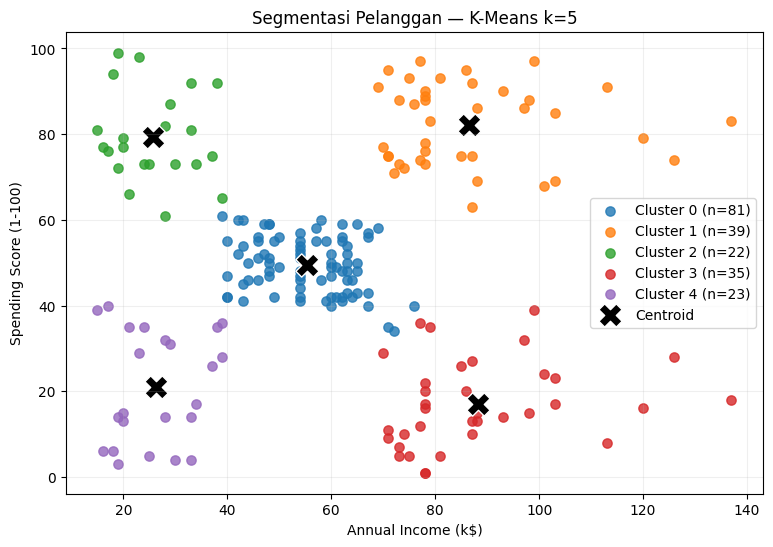

In [4]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

nama_segmen = {
    0:'Pendapatan sedang / belanja sedang',
    1:'Pendapatan tinggi / belanja tinggi',
    2:'Pendapatan rendah / belanja tinggi',
    3:'Pendapatan tinggi / belanja rendah',
    4:'Pendapatan rendah / belanja rendah'
}
segmentasi = df.copy()
segmentasi['Cluster'] = y_kmeans
segmentasi['Segmen'] = segmentasi['Cluster'].map(nama_segmen)
ringkasan = segmentasi.groupby('Cluster').agg(
    Jumlah_Pelanggan=('CustomerID','size'),
    Mean_Income=('Annual Income (k$)','mean'),
    Mean_Spending=('Spending Score (1-100)','mean')
).round(2)
ringkasan['Segmen'] = ringkasan.index.map(nama_segmen)
print('SSE:',round(kmeans.inertia_,4))
print('Silhouette:',round(silhouette_score(X,y_kmeans),4))
display(ringkasan)

plt.figure(figsize=(9,6))
for k in range(5):
    mask = y_kmeans == k
    plt.scatter(X.iloc[mask,0],X.iloc[mask,1],s=45,
                label=f'Cluster {k} (n={mask.sum()})',alpha=0.8)
plt.scatter(centroids[:,0],centroids[:,1],s=280,marker='X',
            c='black',edgecolors='white',label='Centroid')
plt.title('Segmentasi Pelanggan — K-Means k=5')
plt.xlabel('Annual Income (k$)');plt.ylabel('Spending Score (1-100)')
plt.grid(alpha=.2);plt.legend();plt.show()

segmentasi.to_csv('mall_customers_bercluster.csv',index=False)
nilai_k.to_csv('hasil_elbow_silhouette.csv',index=False)
ringkasan.to_csv('ringkasan_cluster_kmeans.csv')

**Interpretasi:** Data pelanggan terbagi dalam lima segmen utama: kelompok sedang–sedang; tinggi–tinggi; rendah–tinggi; tinggi–rendah; dan rendah–rendah. Pemisahan tersebut dapat membantu menyusun strategi pemasaran yang berbeda antarsegmen.

## Bagian B — DBSCAN: Dataset Make Moons

### 1. Pembuatan dan standarisasi dataset

`StandardScaler` digunakan sebagai normalisasi berbasis z-score supaya fitur berada pada skala yang sebanding. Dataset memiliki label asli yang dipakai **hanya untuk evaluasi**, bukan untuk melatih DBSCAN.

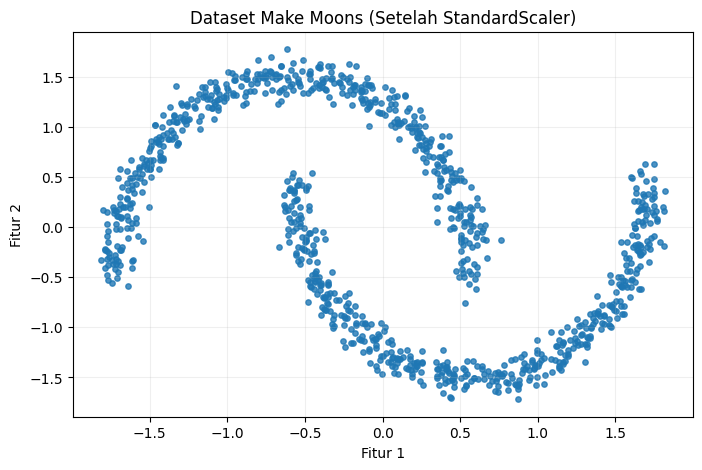

In [5]:
X_moon_raw, labels_true = make_moons(n_samples=1000,noise=0.05,random_state=0)
X_moon = StandardScaler().fit_transform(X_moon_raw)
plt.figure(figsize=(8,5))
plt.scatter(X_moon[:,0],X_moon[:,1],s=15,alpha=.8)
plt.title('Dataset Make Moons (Setelah StandardScaler)')
plt.xlabel('Fitur 1');plt.ylabel('Fitur 2');plt.grid(alpha=.2)
plt.show()

### 2. DBSCAN (eps = 0.2, min_samples = 5)

In [6]:
db = DBSCAN(eps=0.2,min_samples=5).fit(X_moon)
labels = db.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
print('Jumlah cluster:',n_clusters)
print('Jumlah noise:',n_noise)

def evaluasi_dbscan(X,labels_true,labels):
    # Silhouette tidak terdefinisi jika hasil hanya satu kelompok,
    # termasuk kasus semua titik ditandai sebagai noise (-1).
    unique_labels = np.unique(labels)
    silhouette = (silhouette_score(X,labels) if 1 < len(unique_labels) < len(labels)
                  else np.nan)
    return {
        'Homogeneity':homogeneity_score(labels_true,labels),
        'Completeness':completeness_score(labels_true,labels),
        'V-measure':v_measure_score(labels_true,labels),
        'ARI':adjusted_rand_score(labels_true,labels),
        'AMI':adjusted_mutual_info_score(labels_true,labels),
        'Silhouette':silhouette,
    }

print('Hasil evaluasi:')
display(pd.Series(evaluasi_dbscan(X_moon,labels_true,labels)).round(4).to_frame('Nilai'))

Jumlah cluster: 2
Jumlah noise: 0
Hasil evaluasi:


,Nilai
Homogeneity,1.0000
Completeness,1.0000
V-measure,1.0000
ARI,1.0000
AMI,1.0000
Silhouette,0.3916


### 3. Visualisasi klaster

**Titik besar:** core samples; **titik kecil:** non-core/border samples; **titik hitam:** noise (`-1`). Jika tidak ada noise, titik hitam tidak tampak.

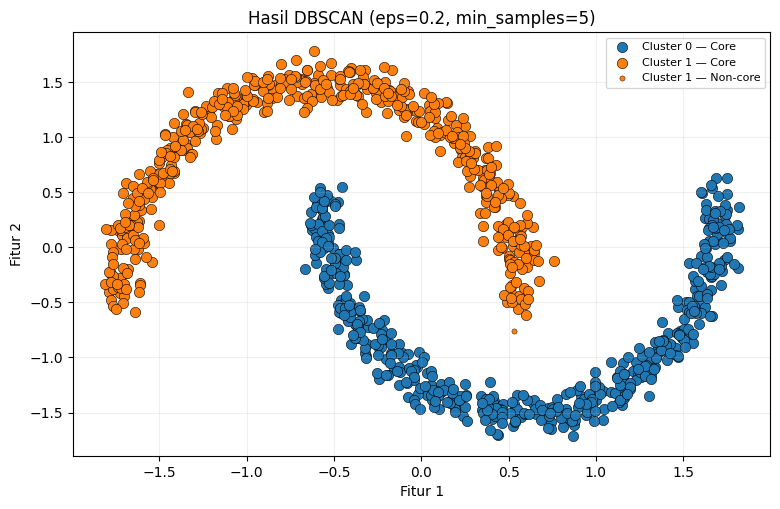

In [7]:
core_samples_mask = np.zeros_like(labels,dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
plt.figure(figsize=(9,5.5))
for label in sorted(set(labels)):
    class_mask = labels == label
    warna = 'black' if label == -1 else plt.cm.tab10(int(label)%10)
    core = class_mask & core_samples_mask
    non_core = class_mask & (~core_samples_mask)
    plt.scatter(X_moon[core,0],X_moon[core,1],s=55,color=warna,
                edgecolor='black',linewidth=.4,
                label=f'Cluster {label} — Core' if label!=-1 else 'Noise')
    if np.any(non_core):
        plt.scatter(X_moon[non_core,0],X_moon[non_core,1],s=14,
                    color=warna,edgecolor='black',linewidth=.3,
                    label=f'Cluster {label} — Non-core' if label!=-1 else 'Noise')
plt.xlabel('Fitur 1');plt.ylabel('Fitur 2')
plt.title('Hasil DBSCAN (eps=0.2, min_samples=5)')
plt.grid(alpha=.2);plt.legend(fontsize=8)
plt.show()

### 4. Eksperimen kombinasi eps dan min_samples (12 konfigurasi)

In [8]:
rows=[]
for eps in [0.05,0.1,0.3,0.5]:
    for min_samples in [3,10,20]:
        model_db = DBSCAN(eps=eps,min_samples=min_samples).fit(X_moon)
        lab=model_db.labels_
        n_clusters_test=len(set(lab)) - (1 if -1 in lab else 0)
        n_noise_test=int(np.sum(lab==-1))
        metrics=evaluasi_dbscan(X_moon,labels_true,lab)
        rows.append({'eps':eps,'min_samples':min_samples,
                     'Jumlah Cluster':n_clusters_test,
                     'Jumlah Noise':n_noise_test,**metrics})
hasil_eksperimen=pd.DataFrame(rows)
display(hasil_eksperimen.round(4))
hasil_eksperimen.to_csv('hasil_eksperimen_dbscan.csv',index=False)

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,67,197,0.8038,0.1549,0.2598,0.0330,0.2464,0.0780
1,0.05,10,0,1000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN
2,0.05,20,0,1000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN
3,0.10,3,3,18,0.9835,0.7084,0.8236,0.8543,0.8232,0.1379
4,0.10,10,9,63,0.9389,0.3583,0.5187,0.4351,0.5169,0.1841
5,0.10,20,6,844,0.1571,0.1534,0.1552,0.0104,0.1515,-0.4091
6,0.30,3,2,0,1.0000,1.0000,1.0000,1.0000,1.0000,0.3916
7,0.30,10,2,0,1.0000,1.0000,1.0000,1.0000,1.0000,0.3916
8,0.30,20,2,0,1.0000,1.0000,1.0000,1.0000,1.0000,0.3916
9,0.50,3,1,0,0.0000,1.0000,0.0000,0.0000,0.0000,NaN


### 5. Perbandingan jumlah cluster dan noise

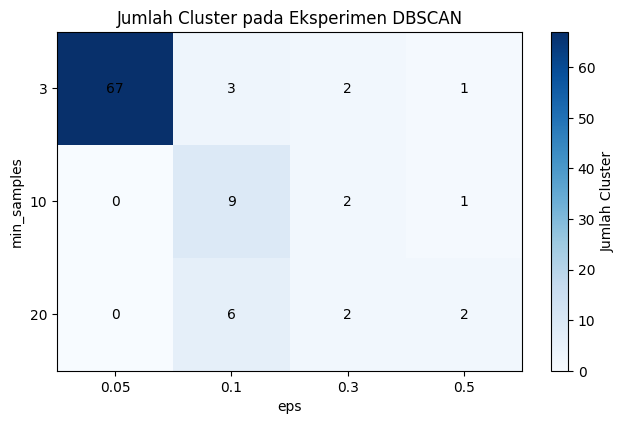

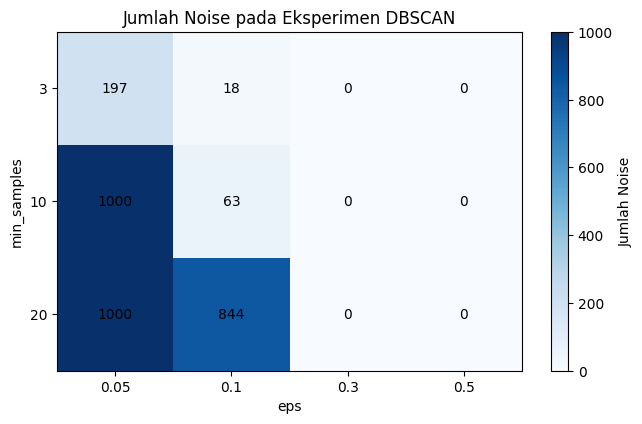

In [9]:
for nama in ['Jumlah Cluster','Jumlah Noise']:
    pivot=hasil_eksperimen.pivot(index='min_samples',columns='eps',values=nama)
    plt.figure(figsize=(7.5,4.4))
    plt.imshow(pivot.values,cmap='Blues',aspect='auto')
    plt.colorbar(label=nama)
    plt.xticks(range(len(pivot.columns)),pivot.columns)
    plt.yticks(range(len(pivot.index)),pivot.index)
    plt.xlabel('eps');plt.ylabel('min_samples');plt.title(nama+' pada Eksperimen DBSCAN')
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            plt.text(j,i,str(int(pivot.values[i,j])),ha='center',va='center')
    plt.show()

### Kesimpulan

**K-Means:** dataset Mall Customers berhasil dibagi menjadi **5 segmen pelanggan** dengan fitur Annual Income dan Spending Score. Jumlah k dipilih berdasarkan Elbow dan Silhouette.

**DBSCAN:** dengan `eps=0.2`, `min_samples=5`, diperoleh **2 cluster dan 0 noise** serta nilai **Homogeneity, Completeness, V-measure, ARI, dan AMI = 1.0**. Kualitas hasil sensitif terhadap parameter: `eps` terlalu kecil menyebabkan fragmentasi atau banyak noise, sedangkan `eps` terlalu besar dapat menggabungkan dua cluster. Tidak setiap konfigurasi memiliki Silhouette yang terdefinisi.

**Catatan evaluasi:** untuk konsistensi dengan contoh modul, Silhouette dihitung menggunakan seluruh `labels` DBSCAN, sehingga noise `-1` ikut diperlakukan sebagai label tersendiri bila ada. Jika semua sampel masuk satu label atau hanya noise, Silhouette dicatat sebagai NaN / tidak terdefinisi.